In [1]:
%pip install pandas numpy matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
PROJECT_DIR = Path.cwd().parent
FILE_PATH = PROJECT_DIR / "data" / "raw" / "Online Retail.xlsx"

print("Notebook location:", Path.cwd())
print("File exists:", FILE_PATH.exists())

df = pd.read_excel(FILE_PATH)
print("Dataset loaded:", df.shape)

Notebook location: c:\Users\ABC\OneDrive\Desktop\qveto_project_1\Demand-Forecasting-Inventory-Optimization-Using-Machine-Learning\notebooks
File exists: True
Dataset loaded: (541909, 8)


In [4]:
display(df.head())
df.info()
display(df.describe(include="all").T)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Unique Values": df.nunique().values
})

display(data_dictionary)

,Column,Data Type,Missing Values,Unique Values
0,InvoiceNo,object,0,25900
1,StockCode,object,0,4070
2,Description,object,1454,4223
3,Quantity,int64,0,722
4,InvoiceDate,datetime64[us],0,23260
5,UnitPrice,float64,0,1630
6,CustomerID,float64,135080,4372
7,Country,str,0,38


In [6]:
data_dictionary.to_csv(
    PROJECT_DIR / "reports" / "data_dictionary.csv",
    index=False
)

In [7]:
quality_report = pd.Series({
    "Total rows": len(df),
    "Total columns": df.shape[1],
    "Duplicate rows": df.duplicated().sum(),
    "Missing descriptions": df["Description"].isna().sum(),
    "Missing customer IDs": df["CustomerID"].isna().sum(),
    "Negative quantities": (df["Quantity"] < 0).sum(),
    "Zero quantities": (df["Quantity"] == 0).sum(),
    "Non-positive prices": (df["UnitPrice"] <= 0).sum(),
    "Cancellation invoices": (
        df["InvoiceNo"].astype(str).str.startswith("C").sum()
    )
})

display(quality_report.to_frame("Count"))

,Count
Total rows,541909
Total columns,8
Duplicate rows,5268
Missing descriptions,1454
Missing customer IDs,135080
Negative quantities,10624
Zero quantities,0
Non-positive prices,2517
Cancellation invoices,9288


In [8]:
quality_report.to_csv(
    PROJECT_DIR / "reports" / "quality_report.csv",
    index=False
)

In [9]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

sales = df[
    df["InvoiceDate"].notna()
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

print("Original rows:", len(df))
print("Rows retained for initial sales analysis:", len(sales))
print("Excluded rows:", len(df) - len(sales))

Original rows: 541909
Rows retained for initial sales analysis: 530104
Excluded rows: 11805


In [10]:
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

sales.to_csv(
    INTERIM_DIR / "cleaned_sales.csv",
    index=False
)

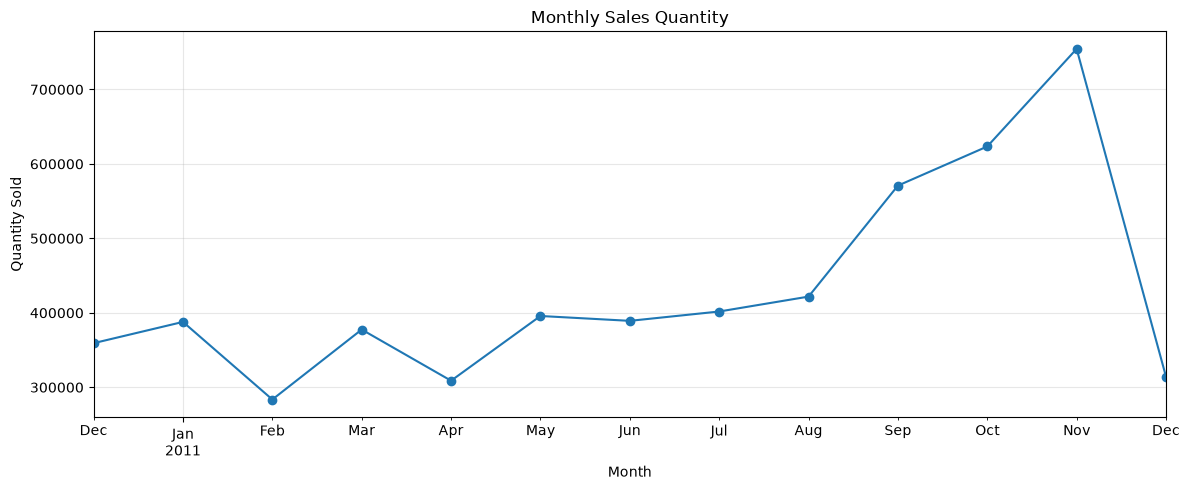

In [11]:
monthly_demand = (
    sales.set_index("InvoiceDate")["Quantity"]
    .resample("MS")
    .sum()
)

monthly_demand.plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly Sales Quantity"
)

plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

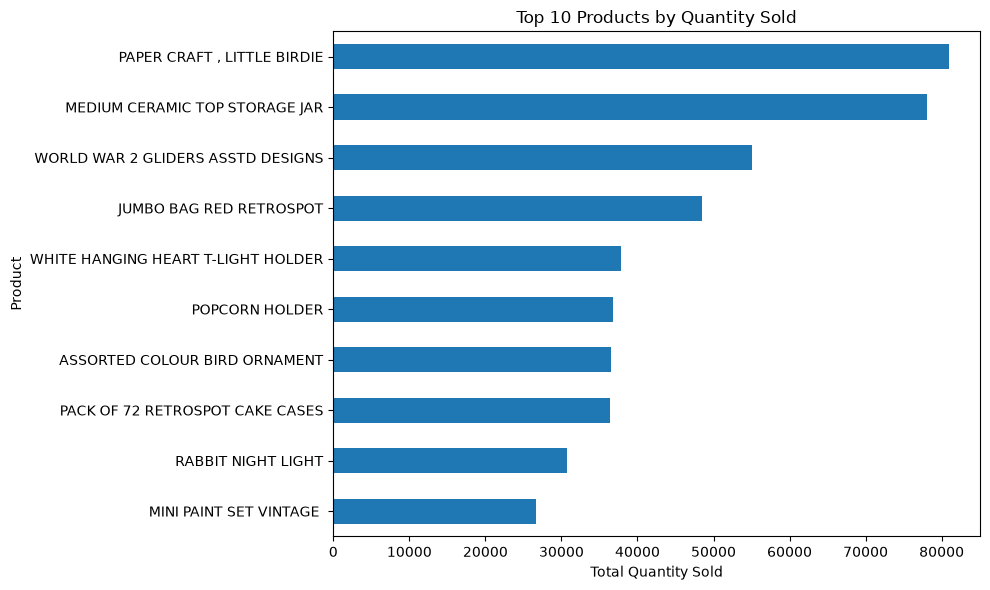

In [12]:
top_products = (
    sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Products by Quantity Sold"
)

plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

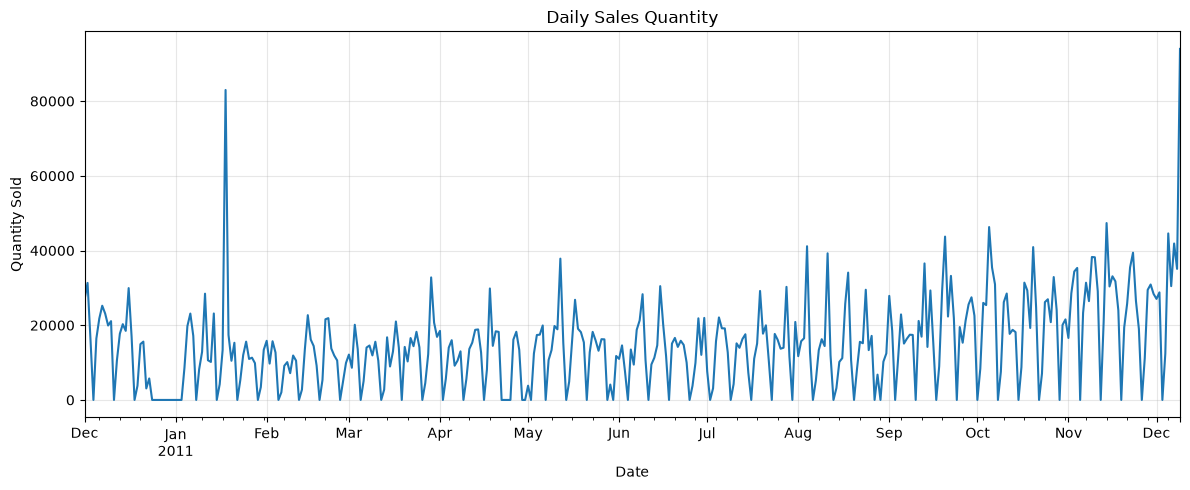

In [13]:
daily_demand = (
    sales.set_index("InvoiceDate")["Quantity"]
    .resample("D")
    .sum()
)

daily_demand.plot(
    figsize=(12, 5),
    title="Daily Sales Quantity"
)

plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

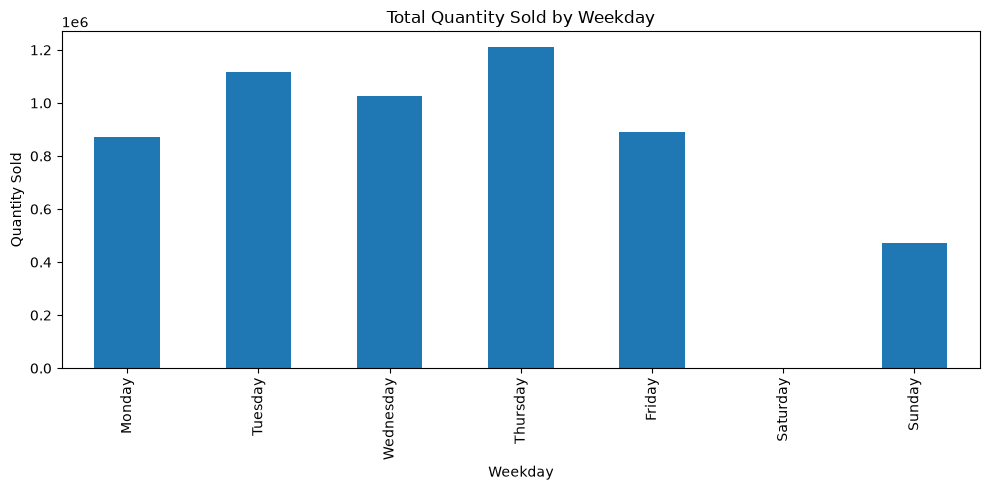

In [14]:
sales["Weekday"] = sales["InvoiceDate"].dt.day_name()

weekday_demand = (
    sales.groupby("Weekday")["Quantity"]
    .sum()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

weekday_demand.plot(
    kind="bar",
    figsize=(10, 5),
    title="Total Quantity Sold by Weekday"
)

plt.ylabel("Quantity Sold")
plt.tight_layout()
plt.show()

In [15]:
print("First transaction:", sales["InvoiceDate"].min())
print("Last transaction:", sales["InvoiceDate"].max())
print("Unique products:", sales["StockCode"].nunique())
print("Countries:", sales["Country"].nunique())

print("Days in date range:", len(daily_demand))
print("Days with no recorded sales:", (daily_demand == 0).sum())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00
Unique products: 3922
Countries: 38
Days in date range: 374
Days with no recorded sales: 69


In [16]:

# Create a clean data-quality summary
quality_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Missing Product Descriptions",
        "Missing Customer IDs",
        "Negative Quantities",
        "Zero Quantities",
        "Non-Positive Unit Prices",
        "Cancellation Invoices"
    ],
    "Value": [
        len(df),
        df.shape[1],
        df.duplicated().sum(),
        df["Description"].isna().sum(),
        df["CustomerID"].isna().sum(),
        (df["Quantity"] < 0).sum(),
        (df["Quantity"] == 0).sum(),
        (df["UnitPrice"] <= 0).sum(),
        df["InvoiceNo"].astype(str).str.startswith("C").sum()
    ]
})

quality_report["Percentage (%)"] = (
    quality_report["Value"] / len(df) * 100
).round(2)

quality_report.loc[
    quality_report["Metric"] == "Total Columns",
    "Percentage (%)"
] = np.nan

# Save only the CSV report
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

quality_report.to_csv(
    REPORT_DIR / "data_quality_report.csv",
    index=False
)

print("Data quality report saved successfully!")
display(quality_report)


Data quality report saved successfully!


,Metric,Value,Percentage (%)
0,Total Rows,541909,100.00
1,Total Columns,8,NaN
2,Duplicate Rows,5268,0.97
3,Missing Product Descriptions,1454,0.27
4,Missing Customer IDs,135080,24.93
5,Negative Quantities,10624,1.96
6,Zero Quantities,0,0.00
7,Non-Positive Unit Prices,2517,0.46
8,Cancellation Invoices,9288,1.71
